In [2]:
import pandas as pd

df = pd.read_pickle("dane.pkl")
print(df.shape)


(421570, 17)


In [3]:
df["Month"] = df["Date"].dt.month
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)

print(df[["Date", "Month", "WeekOfYear"]].head())

        Date  Month  WeekOfYear
0 2010-02-05      2           5
1 2010-02-12      2           6
2 2010-02-19      2           7
3 2010-02-26      2           8
4 2010-03-05      3           9


Podział na dane treningowe i testowe

In [4]:
df["Type_num"] = df["Type"].map({"A": 0, "B": 1, "C": 2})
df["Month"] = df["Date"].dt.month
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)

train = df[df["Date"] < "2012-07-27"]
test = df[df["Date"] >= "2012-07-27"]

train = df[df["Date"] < "2012-07-27"]
test = df[df["Date"] >= "2012-07-27"]

print(train.shape, test.shape)
print(train["Date"].max(), test["Date"].min())

(380107, 20) (41463, 20)
2012-07-20 00:00:00 2012-07-27 00:00:00


In [5]:
rok_temu = df[["Store", "Dept", "Date", "Weekly_Sales"]].copy()
rok_temu["Date"] = rok_temu["Date"] + pd.Timedelta(days=364)
rok_temu = rok_temu.rename(columns={"Weekly_Sales": "baseline"})

test_b = test.merge(rok_temu, on=["Store", "Dept", "Date"], how="left")

print(test_b.shape)
print("brak baseline:", test_b["baseline"].isna().sum())

(41463, 21)
brak baseline: 1029


In [6]:
def wape(rzeczywiste, prognoza):
    return (rzeczywiste - prognoza).abs().sum() / rzeczywiste.abs().sum()

# poziom sklep + dział 
t = test_b.dropna(subset=["baseline"])
print("WAPE sklep+dział:", round(wape(t["Weekly_Sales"], t["baseline"]), 3))

# suma dla całej firmy w każdym tygodniu
suma = test_b.groupby("Date")[["Weekly_Sales", "baseline"]].sum()
print("WAPE suma firmy:", round(wape(suma["Weekly_Sales"], suma["baseline"]), 3))

WAPE sklep+dział: 0.106
WAPE suma firmy: 0.02


In [7]:
bazowy = ["Store", "Dept", "Type_num", "Size", "Month", "WeekOfYear",
                "IsHoliday", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
markdown = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]
calkowity = bazowy + markdown

X_train_baz = train[bazowy].astype(float)
X_test_baz = test[bazowy].astype(float)
X_train_cal = train[calkowity].astype(float)
X_test_cal = test[calkowity].astype(float)

y_train = train["Weekly_Sales"]
y_test = test["Weekly_Sales"]

print(X_train_baz.shape, X_train_cal.shape)

(380107, 11) (380107, 16)


In [8]:
import time
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

modele = {
    "Regresja liniowa": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15,
                                           min_samples_leaf=5, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, max_depth=8, learning_rate=0.1,
                            random_state=42, n_jobs=-1),
}

wyniki = []
for nazwa, model in modele.items():
    start = time.time()
    model.fit(X_train_baz, y_train)
    pred = pd.Series(model.predict(X_test_baz), index=test.index)
    czas = time.time() - start

    suma = pd.DataFrame({"y": y_test, "p": pred, "Date": test["Date"]}).groupby("Date")[["y", "p"]].sum()
    wyniki.append({
        "model": nazwa,
        "WAPE sklep+dział": round(wape(y_test, pred), 3),
        "WAPE suma firmy": round(wape(suma["y"], suma["p"]), 3),
        "czas [s]": round(czas, 1),
    })

print(pd.DataFrame(wyniki).to_string(index=False))

           model  WAPE sklep+dział  WAPE suma firmy  czas [s]
Regresja liniowa             0.940            0.074       0.5
   Random Forest             0.129            0.022     158.5
         XGBoost             0.139            0.011      42.9


In [9]:
model_baz = modele["XGBoost"]
pred_baz = pd.Series(model_baz.predict(X_test_baz), index=test.index)

model_cal = XGBRegressor(n_estimators=300, max_depth=8, learning_rate=0.1,
                         random_state=42, n_jobs=-1)
model_cal.fit(X_train_cal, y_train)
pred_cal = pd.Series(model_cal.predict(X_test_cal), index=test.index)

for nazwa, pred in [("bazowy", pred_baz), ("całkowity", pred_cal)]:
    suma = pd.DataFrame({"y": y_test, "p": pred, "Date": test["Date"]}).groupby("Date")[["y", "p"]].sum()
    print(nazwa, "| sklep+dział:", round(wape(y_test, pred), 3),
          "| suma firmy:", round(wape(suma["y"], suma["p"]), 3))

bazowy | sklep+dział: 0.139 | suma firmy: 0.011
całkowity | sklep+dział: 0.143 | suma firmy: 0.016


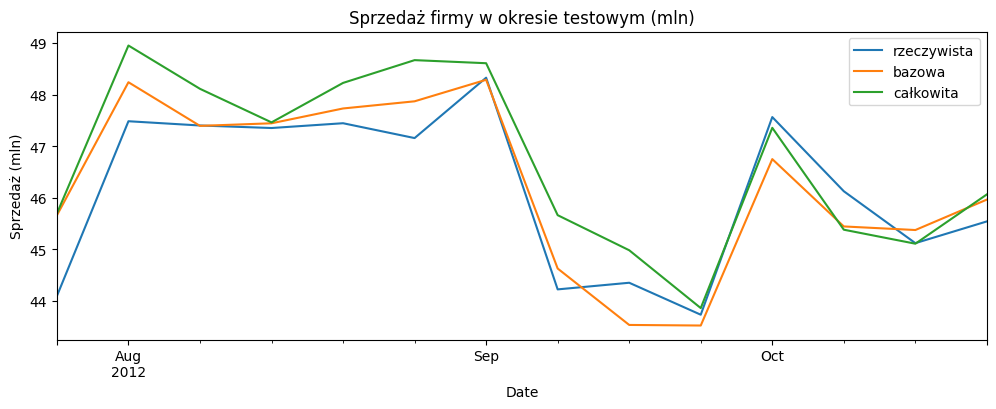

In [10]:
import matplotlib.pyplot as plt

porownanie = pd.DataFrame({
    "rzeczywista": y_test,
    "bazowa": pred_baz,
    "całkowita": pred_cal,
    "Date": test["Date"],
}).groupby("Date").sum()

(porownanie / 1_000_000).plot(figsize=(12, 4),
                              title="Sprzedaż firmy w okresie testowym (mln)")
plt.ylabel("Sprzedaż (mln)")
plt.show()

In [11]:
X_all_baz = df[bazowy].astype(float)
X_all_cal = df[calkowity].astype(float)
y_all = df["Weekly_Sales"]

model_baz_final = XGBRegressor(n_estimators=300, max_depth=8, learning_rate=0.1,
                               random_state=42, n_jobs=-1)
model_baz_final.fit(X_all_baz, y_all)

model_cal_final = XGBRegressor(n_estimators=300, max_depth=8, learning_rate=0.1,
                               random_state=42, n_jobs=-1)
model_cal_final.fit(X_all_cal, y_all)

print("gotowe")

gotowe


In [13]:
import joblib
from pathlib import Path

MODELE = Path(r"C:\Users\Alicja\Desktop\kurs-datascience\Data Science\Prognoza_sprzedazy\modele")
MODELE.mkdir(exist_ok=True)

joblib.dump(model_baz_final, MODELE / "model_bazowy.joblib")
joblib.dump(model_cal_final, MODELE / "model_calkowity.joblib")
print("zapisano modele w:", MODELE)

zapisano modele w: C:\Users\Alicja\Desktop\kurs-datascience\Data Science\Prognoza_sprzedazy\modele
